# Loan Approval Prediction

**Goal:** predict whether a loan application will be approved (binary classification) and evaluate properly on imbalanced data, focusing on **precision, recall and F1-score**.

**Bonus:** address class imbalance (class weights + SMOTE) and compare **Logistic Regression vs Decision Tree**.

**Dataset:** [Loan-Approval-Prediction-Dataset (Kaggle)](https://www.kaggle.com/datasets/architsharma01/loan-approval-prediction-dataset) -> download `loan_approval_dataset.csv` and put it next to this notebook (or set `DATA_PATH` below).

The notebook is written to also work with the other popular Kaggle loan dataset (with `Loan_Status` Y/N and real missing values): the target and column types are detected automatically.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score, roc_auc_score,
                             precision_recall_curve, average_precision_score)

# SMOTE lives in imbalanced-learn:  pip install imbalanced-learn
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, SMOTENC

import warnings; warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
DATA_PATH = "loan_approval_dataset.csv"

## 1. Load the data

In [2]:
df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()                      # this dataset has leading spaces in column names
obj_cols = df.select_dtypes("object").columns
df[obj_cols] = df[obj_cols].apply(lambda s: s.str.strip())   # ... and in the values
print(df.shape)
df.head()

(4269, 13)


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   loan_id                   4269 non-null   int64 
 1   no_of_dependents          4269 non-null   int64 
 2   education                 4269 non-null   object
 3   self_employed             4269 non-null   object
 4   income_annum              4269 non-null   int64 
 5   loan_amount               4269 non-null   int64 
 6   loan_term                 4269 non-null   int64 
 7   cibil_score               4269 non-null   int64 
 8   residential_assets_value  4269 non-null   int64 
 9   commercial_assets_value   4269 non-null   int64 
 10  luxury_assets_value       4269 non-null   int64 
 11  bank_asset_value          4269 non-null   int64 
 12  loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB


In [4]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
loan_id,4269.0,NaN,NaN,NaN,2135.0,1232.498479,1.0,1068.0,2135.0,3202.0,4269.0
no_of_dependents,4269.0,NaN,NaN,NaN,2.498712,1.69591,0.0,1.0,3.0,4.0,5.0
education,4269,2,Graduate,2144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
self_employed,4269,2,Yes,2150,NaN,NaN,NaN,NaN,NaN,NaN,NaN
income_annum,4269.0,NaN,NaN,NaN,5059123.916608,2806839.831818,200000.0,2700000.0,5100000.0,7500000.0,9900000.0
loan_amount,4269.0,NaN,NaN,NaN,15133450.456781,9043362.984843,300000.0,7700000.0,14500000.0,21500000.0,39500000.0
loan_term,4269.0,NaN,NaN,NaN,10.900445,5.709187,2.0,6.0,10.0,16.0,20.0
cibil_score,4269.0,NaN,NaN,NaN,599.936051,172.430401,300.0,453.0,600.0,748.0,900.0
residential_assets_value,4269.0,NaN,NaN,NaN,7472616.537831,6503636.587664,-100000.0,2200000.0,5600000.0,11300000.0,29100000.0
commercial_assets_value,4269.0,NaN,NaN,NaN,4973155.305692,4388966.089638,0.0,1300000.0,3700000.0,7600000.0,19400000.0


## 2. Target, ID column and class balance
We find the target column, map it to **1 = Approved, 0 = Rejected**, and drop the ID column (it carries no signal and would only add noise).

loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64 

loan_status
Approved    0.622
Rejected    0.378
Name: count, dtype: float64


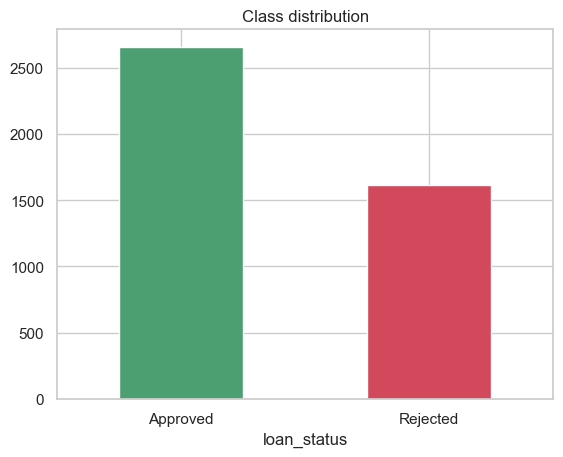

In [5]:
TARGET = next(c for c in df.columns if c.lower() in ("loan_status", "loan status"))
ID_COLS = [c for c in df.columns if c.lower() in ("loan_id", "id")]

positive_labels = {"approved", "y", "yes", "1"}
df[TARGET] = df[TARGET].astype(str).str.lower().isin(positive_labels).astype(int)
df = df.drop(columns=ID_COLS)

counts = df[TARGET].value_counts().rename({1: "Approved", 0: "Rejected"})
print(counts, "\n")
print((counts / len(df)).round(3))
counts.plot(kind="bar", color=["#4C9F70", "#D1495B"], rot=0, title="Class distribution")
plt.show()

> **Why this matters:** if the classes are skewed, *accuracy is misleading* (a model that always predicts the majority class already scores high). That's why we report **precision, recall, F1** per class, plus PR-AUC / ROC-AUC.

## 3. Missing values and quick EDA

In [6]:
missing = df.isna().sum()
print(missing[missing > 0] if missing.any() else "No missing values in this file - the imputers in the pipeline are still included so the code is robust.")

No missing values in this file - the imputers in the pipeline are still included so the code is robust.


Numeric    : ['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']
Categorical: ['education', 'self_employed']


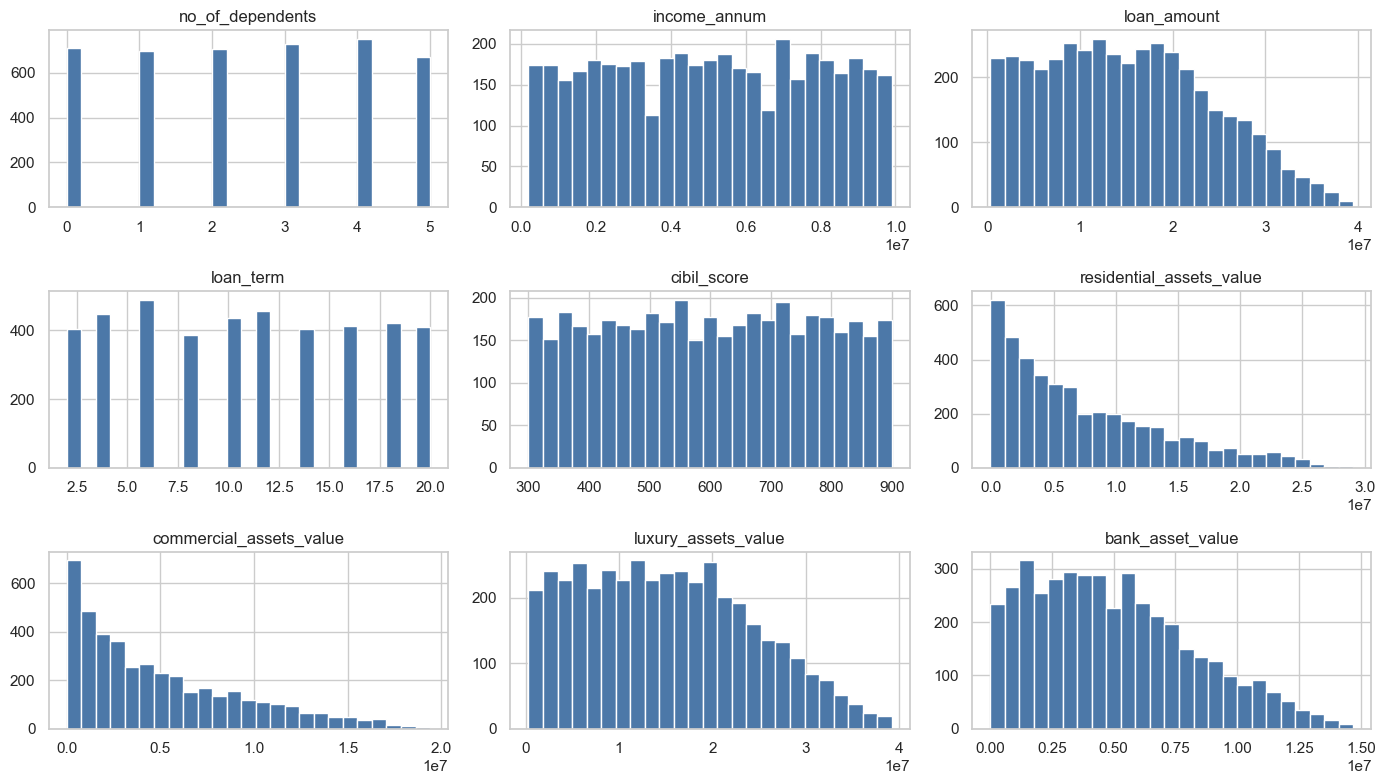

In [7]:
num_cols = df.drop(columns=TARGET).select_dtypes(include="number").columns.tolist()
cat_cols = df.drop(columns=TARGET).select_dtypes(exclude="number").columns.tolist()
print("Numeric    :", num_cols)
print("Categorical:", cat_cols)

df[num_cols].hist(bins=25, figsize=(14, 8), color="#4C78A8")
plt.tight_layout(); plt.show()

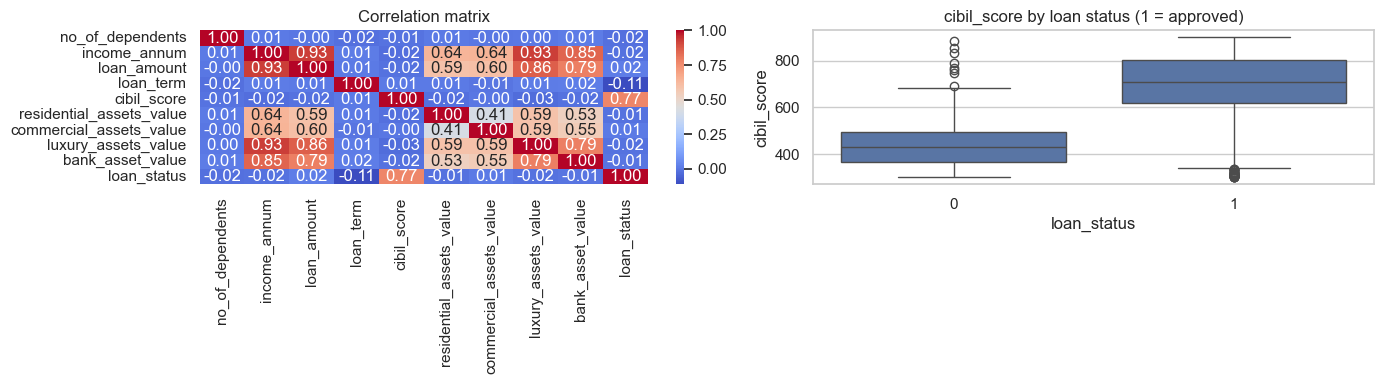

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.heatmap(df[num_cols + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[0])
axes[0].set_title("Correlation matrix")
score_col = next((c for c in num_cols if "cibil" in c.lower() or "credit" in c.lower()), num_cols[0])
sns.boxplot(data=df, x=TARGET, y=score_col, ax=axes[1])
axes[1].set_title(f"{score_col} by loan status (1 = approved)")
plt.tight_layout(); plt.show()

## 4. Train / test split
A **stratified** split keeps the class ratio identical in train and test. The test set is never touched by SMOTE or tuning.

In [9]:
X = df.drop(columns=TARGET)
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)
print("Train approved share:", y_train.mean().round(3), "| Test approved share:", y_test.mean().round(3))

(3415, 11) (854, 11)
Train approved share: 0.622 | Test approved share: 0.622


## 5. Preprocessing (missing values + encoding)
- **Numeric:** median imputation + standard scaling (scaling matters for logistic regression, not for trees, but it's harmless).
- **Categorical:** most-frequent imputation + one-hot encoding.

Everything is inside a `ColumnTransformer`, so it is fitted **only on training data** (no leakage) and applied identically at prediction time.

In [10]:
numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("scaler", StandardScaler())])
categorical_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                             ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary"))])

preprocess = ColumnTransformer([("num", numeric_pipe, num_cols),
                                ("cat", categorical_pipe, cat_cols)])

## 6. Baseline: Logistic Regression
First a simple model with no imbalance handling, to have something to beat.

===== LogReg - baseline =====
              precision    recall  f1-score   support

Rejected (0)      0.903     0.867     0.885       323
Approved (1)      0.921     0.944     0.932       531

    accuracy                          0.915       854
   macro avg      0.912     0.905     0.908       854
weighted avg      0.914     0.915     0.914       854



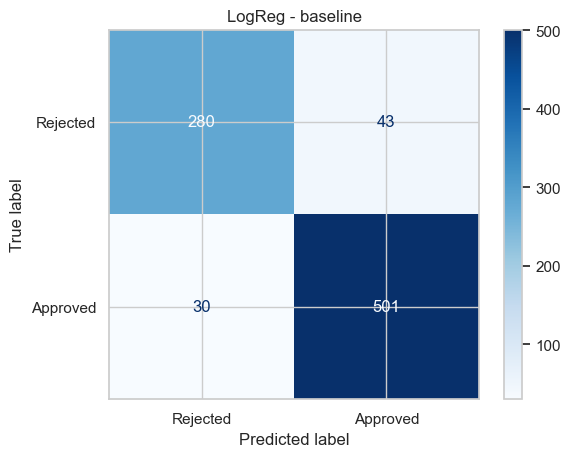

In [11]:
def evaluate(name, model, X_te=X_test, y_te=y_test, show_cm=True):
    """Print the full report and return a dict of headline metrics."""
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    print(f"===== {name} =====")
    print(classification_report(y_te, pred, target_names=["Rejected (0)", "Approved (1)"], digits=3))
    if show_cm:
        ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=["Rejected", "Approved"], cmap="Blues")
        plt.title(name); plt.show()
    return {"Model": name,
            "Precision (macro)": precision_score(y_te, pred, average="macro"),
            "Recall (macro)": recall_score(y_te, pred, average="macro"),
            "F1 (macro)": f1_score(y_te, pred, average="macro"),
            "F1 (Rejected)": f1_score(y_te, pred, pos_label=0),
            "ROC-AUC": roc_auc_score(y_te, proba),
            "PR-AUC": average_precision_score(y_te, proba)}

results = []
logreg_base = Pipeline([("prep", preprocess),
                        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]).fit(X_train, y_train)
results.append(evaluate("LogReg - baseline", logreg_base))

## 7. Handling class imbalance 
Two techniques, both applied **only to the training data**:

1. **Class weights** (`class_weight="balanced"`): the loss penalises mistakes on the minority class more.
2. **SMOTE**: creates synthetic minority samples by interpolating between neighbours. It sits *inside* an `imblearn` pipeline so that it runs only on the training folds during cross-validation (never on validation/test data).

Note that SMOTE runs after one-hot encoding here; for pure one-hot features the interpolated values can be fractional, which is a known limitation (`SMOTENC` is an alternative if you SMOTE before encoding).

===== LogReg - class_weight =====
              precision    recall  f1-score   support

Rejected (0)      0.877     0.929     0.902       323
Approved (1)      0.955     0.921     0.938       531

    accuracy                          0.924       854
   macro avg      0.916     0.925     0.920       854
weighted avg      0.926     0.924     0.924       854



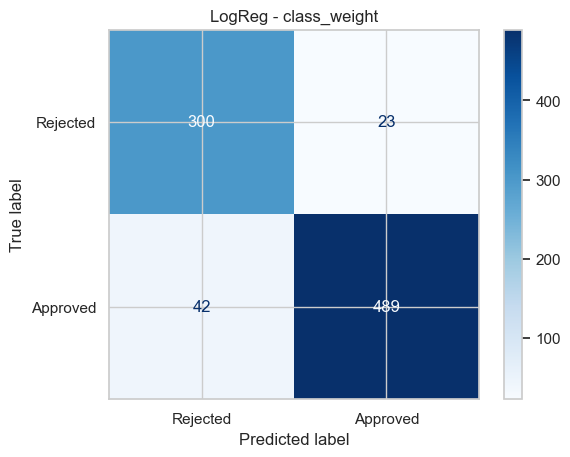

===== LogReg - SMOTE =====
              precision    recall  f1-score   support

Rejected (0)      0.879     0.920     0.899       323
Approved (1)      0.950     0.923     0.936       531

    accuracy                          0.922       854
   macro avg      0.914     0.921     0.917       854
weighted avg      0.923     0.922     0.922       854



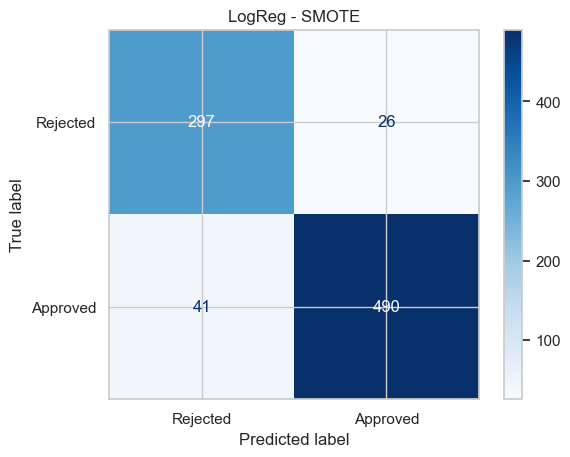

In [12]:
logreg_bal = Pipeline([("prep", preprocess),
                       ("clf", LogisticRegression(max_iter=1000, class_weight="balanced",
                                                  random_state=RANDOM_STATE))]).fit(X_train, y_train)
results.append(evaluate("LogReg - class_weight", logreg_bal))

logreg_smote = ImbPipeline([("prep", preprocess),
                            ("smote", SMOTE(random_state=RANDOM_STATE)),
                            ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]).fit(X_train, y_train)
results.append(evaluate("LogReg - SMOTE", logreg_smote))

## 8. Decision Tree (with and without imbalance handling)

===== Tree - baseline =====
              precision    recall  f1-score   support

Rejected (0)      0.946     0.972     0.959       323
Approved (1)      0.983     0.966     0.974       531

    accuracy                          0.968       854
   macro avg      0.964     0.969     0.967       854
weighted avg      0.969     0.968     0.968       854



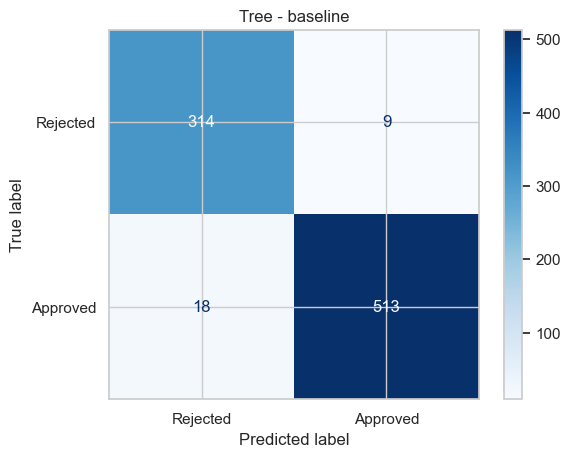

===== Tree - class_weight =====
              precision    recall  f1-score   support

Rejected (0)      0.952     0.985     0.968       323
Approved (1)      0.990     0.970     0.980       531

    accuracy                          0.975       854
   macro avg      0.971     0.977     0.974       854
weighted avg      0.976     0.975     0.975       854



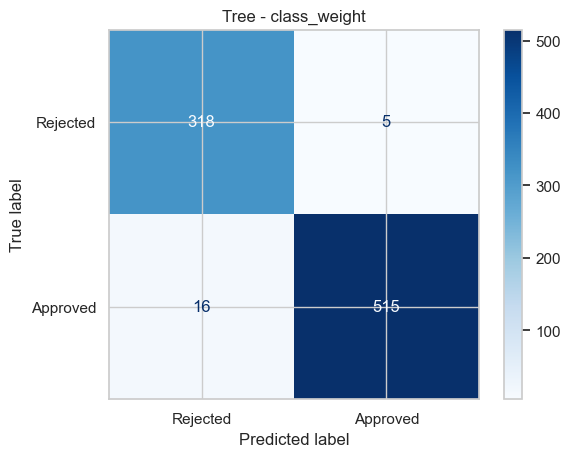

===== Tree - SMOTE =====
              precision    recall  f1-score   support

Rejected (0)      0.949     0.975     0.962       323
Approved (1)      0.985     0.968     0.976       531

    accuracy                          0.971       854
   macro avg      0.967     0.972     0.969       854
weighted avg      0.971     0.971     0.971       854



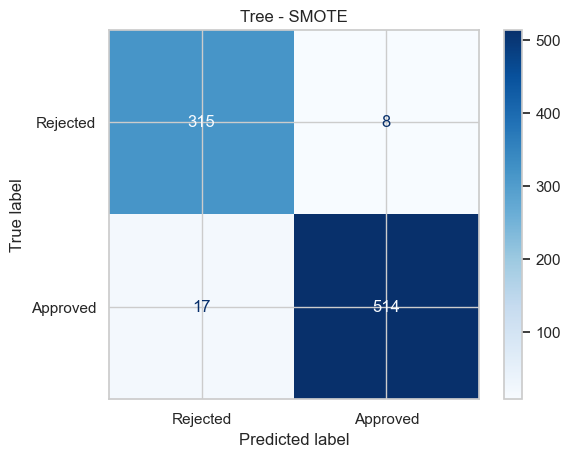

In [13]:
tree_base = Pipeline([("prep", preprocess),
                      ("clf", DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE))]).fit(X_train, y_train)
results.append(evaluate("Tree - baseline", tree_base))

tree_bal = Pipeline([("prep", preprocess),
                     ("clf", DecisionTreeClassifier(max_depth=5, class_weight="balanced",
                                                    random_state=RANDOM_STATE))]).fit(X_train, y_train)
results.append(evaluate("Tree - class_weight", tree_bal))

tree_smote = ImbPipeline([("prep", preprocess),
                          ("smote", SMOTE(random_state=RANDOM_STATE)),
                          ("clf", DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE))]).fit(X_train, y_train)
results.append(evaluate("Tree - SMOTE", tree_smote))

## 9. Hyperparameter tuning (optimising F1 on the minority class)
We tune with **stratified 5-fold CV** and score on `f1_macro`, so neither class can be ignored. Change the scoring if the business cares about something else (e.g. `recall` of rejected loans = catching risky applicants).

Best LogReg: {'clf__C': 0.01} | CV F1-macro: 0.9167
Best Tree  : {'clf__criterion': 'entropy', 'clf__max_depth': None, 'clf__min_samples_leaf': 10} | CV F1-macro: 0.9761
===== LogReg - tuned =====
              precision    recall  f1-score   support

Rejected (0)      0.876     0.963     0.917       323
Approved (1)      0.976     0.917     0.946       531

    accuracy                          0.934       854
   macro avg      0.926     0.940     0.932       854
weighted avg      0.938     0.934     0.935       854



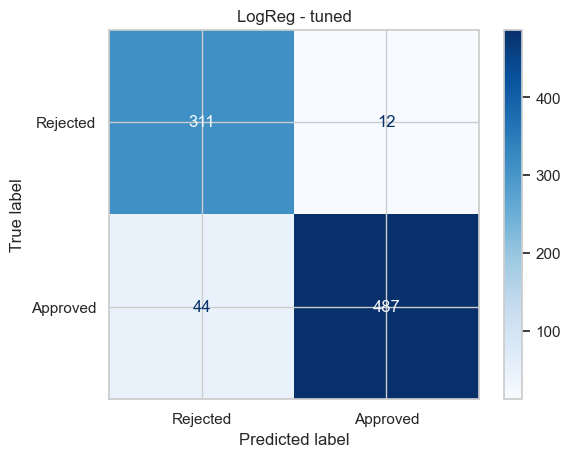

===== Tree - tuned =====
              precision    recall  f1-score   support

Rejected (0)      0.988     0.978     0.983       323
Approved (1)      0.987     0.992     0.990       531

    accuracy                          0.987       854
   macro avg      0.987     0.985     0.986       854
weighted avg      0.987     0.987     0.987       854



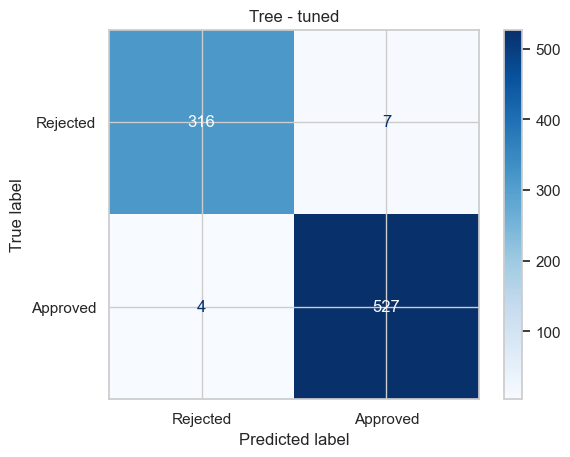

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

lr_search = GridSearchCV(
    Pipeline([("prep", preprocess), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))]),
    {"clf__C": [0.01, 0.1, 1, 10, 100]}, scoring="f1_macro", cv=cv, n_jobs=-1).fit(X_train, y_train)

dt_search = GridSearchCV(
    Pipeline([("prep", preprocess), ("clf", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE))]),
    {"clf__max_depth": [3, 4, 5, 7, 10, None],
     "clf__min_samples_leaf": [1, 5, 10, 20],
     "clf__criterion": ["gini", "entropy"]},
    scoring="f1_macro", cv=cv, n_jobs=-1).fit(X_train, y_train)

print("Best LogReg:", lr_search.best_params_, "| CV F1-macro:", round(lr_search.best_score_, 4))
print("Best Tree  :", dt_search.best_params_, "| CV F1-macro:", round(dt_search.best_score_, 4))

results.append(evaluate("LogReg - tuned", lr_search.best_estimator_))
results.append(evaluate("Tree - tuned", dt_search.best_estimator_))

## 10. Model comparison on the held-out test set

In [15]:
res = pd.DataFrame(results).set_index("Model").round(3)
res.sort_values("F1 (macro)", ascending=False).style.background_gradient(cmap="Greens", axis=0)

,Precision (macro),Recall (macro),F1 (macro),F1 (Rejected),ROC-AUC,PR-AUC
Model,,,,,,
Tree - tuned,0.987000,0.985000,0.986000,0.983000,0.995000,0.994000
Tree - class_weight,0.971000,0.977000,0.974000,0.968000,0.994000,0.993000
Tree - SMOTE,0.967000,0.972000,0.969000,0.962000,0.993000,0.992000
Tree - baseline,0.964000,0.969000,0.967000,0.959000,0.988000,0.988000
LogReg - tuned,0.926000,0.940000,0.932000,0.917000,0.974000,0.986000
LogReg - class_weight,0.916000,0.925000,0.920000,0.902000,0.973000,0.985000
LogReg - SMOTE,0.914000,0.921000,0.917000,0.899000,0.973000,0.985000
LogReg - baseline,0.912000,0.905000,0.908000,0.885000,0.973000,0.985000


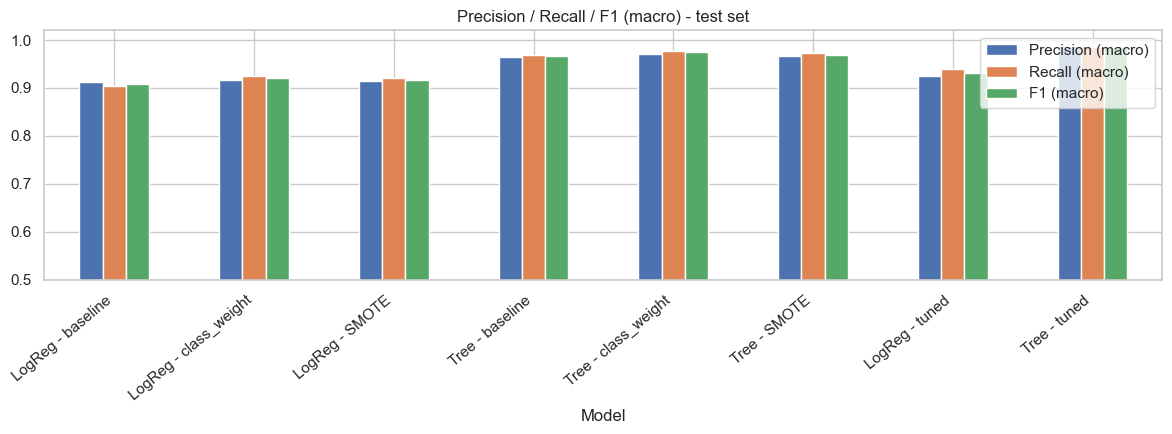

In [16]:
res[["Precision (macro)", "Recall (macro)", "F1 (macro)"]].plot(kind="bar", figsize=(12, 4.5), ylim=(0.5, 1.02))
plt.title("Precision / Recall / F1 (macro) - test set")
plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()

### Cross-validated check (more reliable than a single split)

In [17]:
scoring = {"precision": "precision_macro", "recall": "recall_macro", "f1": "f1_macro"}
candidates = {"LogReg - tuned": lr_search.best_estimator_,
              "Tree - tuned": dt_search.best_estimator_,
              "LogReg - SMOTE": logreg_smote,
              "Tree - SMOTE": tree_smote}
rows = []
for name, est in candidates.items():
    s = cross_validate(est, X, y, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"Model": name, **{k: f"{s['test_'+k].mean():.3f} +/- {s['test_'+k].std():.3f}" for k in scoring}})
pd.DataFrame(rows).set_index("Model")

,precision,recall,f1
Model,,,
LogReg - tuned,0.917 +/- 0.008,0.934 +/- 0.006,0.923 +/- 0.008
Tree - tuned,0.977 +/- 0.006,0.977 +/- 0.004,0.977 +/- 0.005
LogReg - SMOTE,0.914 +/- 0.008,0.924 +/- 0.008,0.918 +/- 0.008
Tree - SMOTE,0.964 +/- 0.006,0.973 +/- 0.004,0.968 +/- 0.005


## 11. Precision-Recall curves and threshold tuning

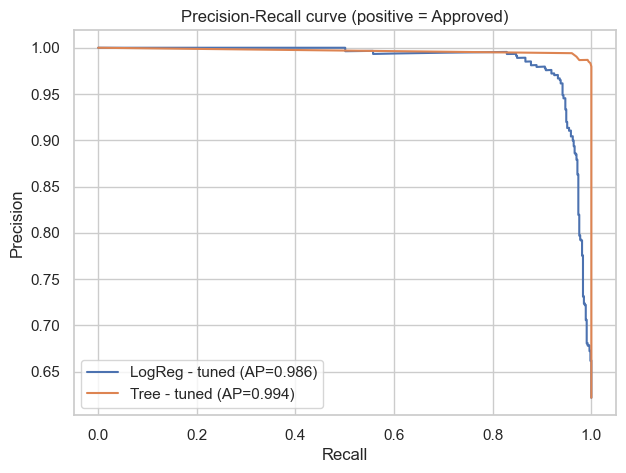

In [18]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, est in {"LogReg - tuned": lr_search.best_estimator_, "Tree - tuned": dt_search.best_estimator_}.items():
    p, r, _ = precision_recall_curve(y_test, est.predict_proba(X_test)[:, 1])
    ax.plot(r, p, label=f"{name} (AP={average_precision_score(y_test, est.predict_proba(X_test)[:, 1]):.3f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title("Precision-Recall curve (positive = Approved)")
ax.legend(); plt.show()

In [19]:
# The default 0.5 threshold is not sacred. Pick the threshold that maximises F1 for the Approved class
# (in a real project choose it on a validation set, or by business cost of a bad approval vs a missed one).
best = lr_search.best_estimator_
proba = best.predict_proba(X_test)[:, 1]
p, r, t = precision_recall_curve(y_test, proba)
f1s = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
thr = t[f1s.argmax()]
print(f"Best threshold = {thr:.3f}  (F1 approved = {f1s.max():.3f})")
print(classification_report(y_test, (proba >= thr).astype(int), target_names=["Rejected", "Approved"], digits=3))

Best threshold = 0.458  (F1 approved = 0.951)
              precision    recall  f1-score   support

    Rejected      0.907     0.938     0.922       323
    Approved      0.962     0.942     0.951       531

    accuracy                          0.940       854
   macro avg      0.934     0.940     0.937       854
weighted avg      0.941     0.940     0.940       854



## 12. Interpretation

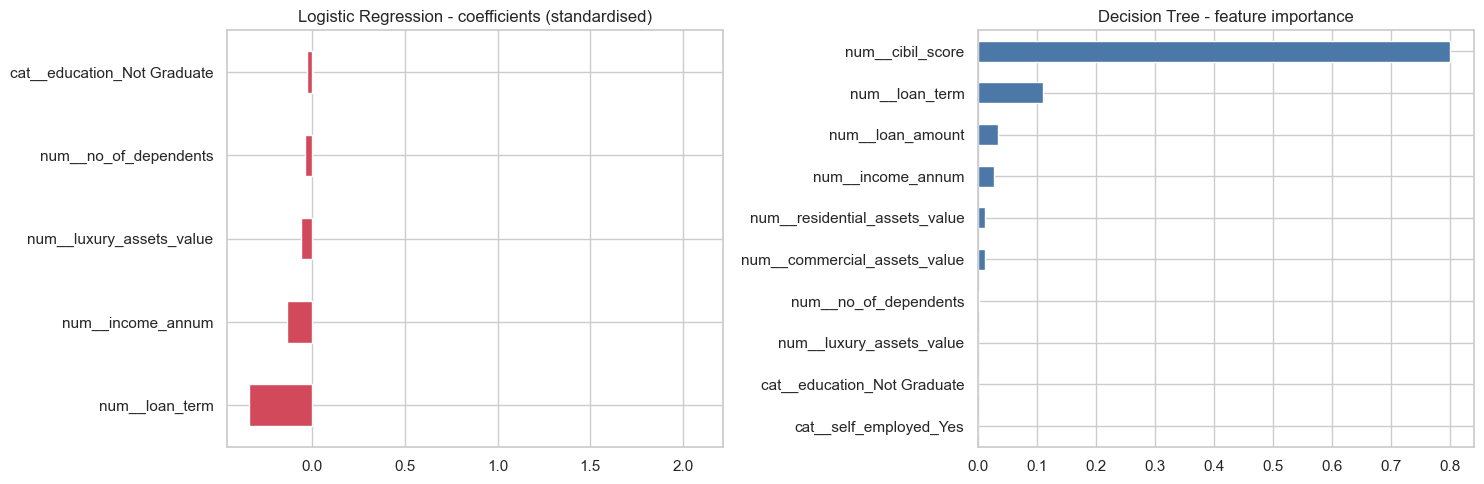

In [20]:
feat_names = lr_search.best_estimator_.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lr_search.best_estimator_.named_steps["clf"].coef_[0], index=feat_names).sort_values()
imps = pd.Series(dt_search.best_estimator_.named_steps["clf"].feature_importances_, index=feat_names).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
coefs.tail(10).plot(kind="barh", ax=axes[0], color="#4C9F70", title="Logistic Regression - coefficients (standardised)")
coefs.head(5).plot(kind="barh", ax=axes[0], color="#D1495B")
imps.tail(10).plot(kind="barh", ax=axes[1], color="#4C78A8", title="Decision Tree - feature importance")
plt.tight_layout(); plt.show()

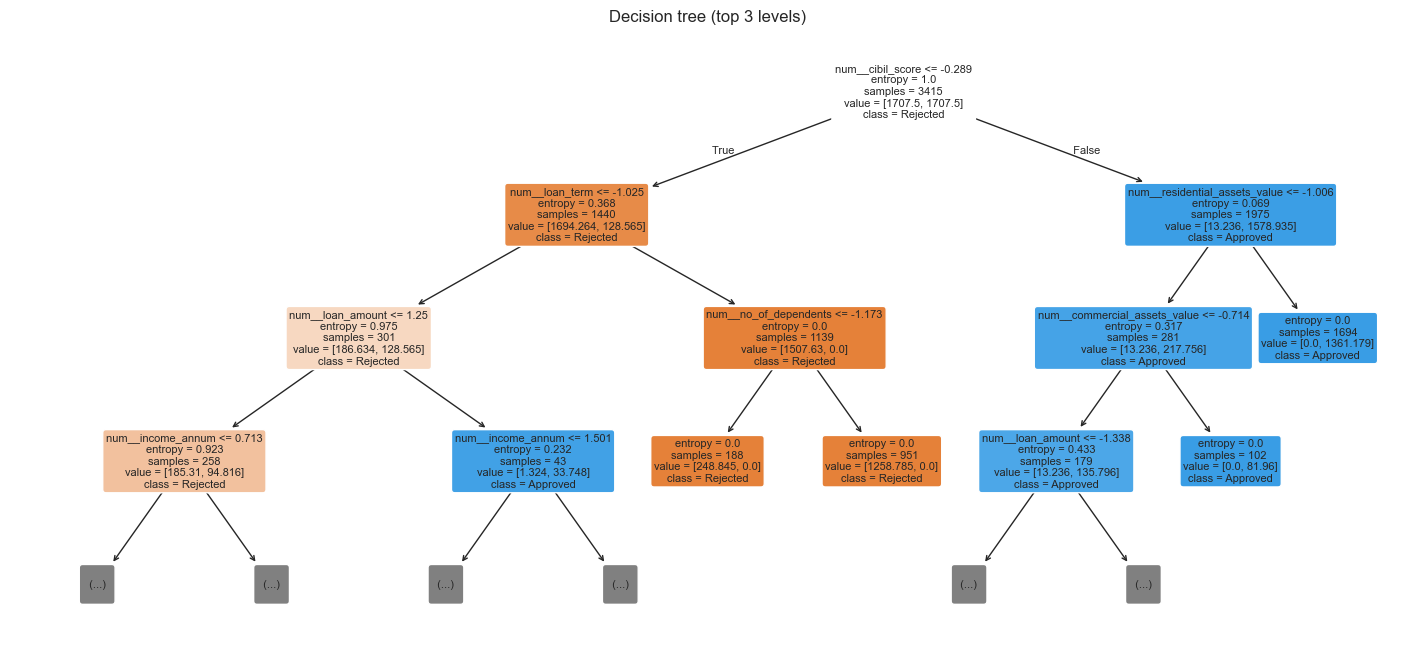

In [21]:
dt_clf = dt_search.best_estimator_.named_steps["clf"]
plt.figure(figsize=(18, 8))
plot_tree(dt_clf, feature_names=feat_names, class_names=["Rejected", "Approved"],
          filled=True, rounded=True, max_depth=3, fontsize=8)
plt.title("Decision tree (top 3 levels)"); plt.show()

## 13. Conclusions
Fill these in with your actual numbers after running the notebook:

- **Imbalance:** accuracy alone hides how well the minority class is handled; per-class precision/recall/F1 and PR-AUC give the honest picture.
- **Class weights vs SMOTE:** compare the "baseline", "class_weight" and "SMOTE" rows in section 10. Typically they trade a little precision for higher recall on the minority class; on a mildly imbalanced dataset the gain is often small.
- **Logistic Regression vs Decision Tree:** logistic regression is simple, stable and interpretable through coefficients; the tree captures non-linear rules (e.g. credit-score cut-offs) and is easy to explain visually, but is prone to overfitting without depth / leaf-size limits.
- **Most influential features:** see section 12 (credit score is usually dominant in this dataset).
- **Next steps:** try Random Forest / gradient boosting, calibrate probabilities, and choose the decision threshold from the real cost of a wrongly approved vs wrongly rejected loan.